<>:113: SyntaxWarning: invalid escape sequence '\m'
<>:113: SyntaxWarning: invalid escape sequence '\m'
C:\Users\kboro\AppData\Local\Temp\ipykernel_16464\2707488976.py:113: SyntaxWarning: invalid escape sequence '\m'
  plt.colorbar(label='Instantaneous Neural Activity $\mathrm{Re}(z_j)$')


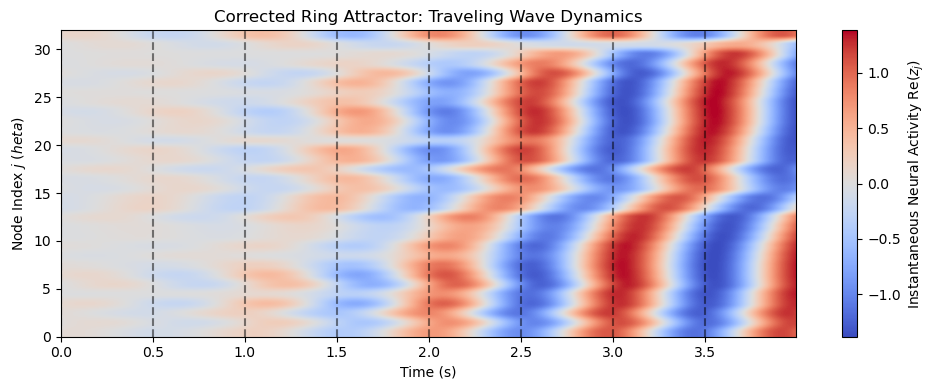

In [155]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

class HopfRingAttractor:
    def __init__(self, num_nodes=32, omega0=2.0 * np.pi, alpha=1.0, beta=-1.0, 
                 w_sym=1.5, w_asym=0.5):
        self.N = num_nodes
        self.omega0 = omega0
        self.alpha = alpha
        self.beta = beta
        
        self.thetas = np.linspace(0, 2 * np.pi, self.N, endpoint=False)
        
        theta_i, theta_j = np.meshgrid(self.thetas, self.thetas, indexing='ij')
        diff = theta_i - theta_j
        
        self.W_sym = w_sym * np.cos(diff) / self.N
        self.W_asym = w_asym * np.sin(diff) / self.N
        self.W = self.W_sym + self.W_asym

    def _dynamics(self, t, state, external_input_fn=None):
        u = state[:self.N]
        v = state[self.N:]
        
        z = u + 1j * v
        r_sq = np.abs(z)**2
        
        dz_dt_intrinsic = z * (self.alpha + 1j * self.omega0 + self.beta * r_sq)
        dz_dt_recurrent = np.dot(self.W, z)
        
        dz_dt = dz_dt_intrinsic + dz_dt_recurrent
        
        if external_input_fn is not None:
            I_t = external_input_fn(t, self.thetas)
            dz_dt += I_t
            
        du_dt = np.real(dz_dt)
        dv_dt = np.imag(dz_dt)
        
        return np.concatenate([du_dt, dv_dt])

    def simulate(self, t_span, dt=0.001, external_input_fn=None, initial_state=None):
        t_eval = np.arange(t_span[0], t_span[1], dt)
        
        if initial_state is None:
            u0 = 0.05 * np.random.randn(self.N)
            v0 = 0.05 * np.random.randn(self.N)
            initial_state = np.concatenate([u0, v0])
            
        sol = solve_ivp(
            fun=lambda t, y: self._dynamics(t, y, external_input_fn),
            t_span=t_span,
            y0=initial_state,
            t_eval=t_eval,
            method='RK45'
        )
        
        u_traj = sol.y[:self.N, :]
        v_traj = sol.y[self.N:, :]
        
        z_traj = u_traj + 1j * v_traj
        r_traj = np.abs(z_traj)
        phi_traj = np.angle(z_traj)
        
        return {
            't': sol.t,
            'r': r_traj,
            'phi': phi_traj,
            'z': z_traj
        }

def create_metronome_fn(bpm=120, intensity=1.5, pulse_width=0.015, target_node_idx=0):
    period = 60.0 / bpm
    
    def input_fn(t, thetas):
        t_mod = t % period
        temporal_pulse = intensity * np.exp(-0.5 * (t_mod / pulse_width)**2)
        
        N = len(thetas)
        node_indices = np.arange(N)
        dist = np.abs(node_indices - target_node_idx)
        dist = np.minimum(dist, N - dist)
        spatial_weight = np.exp(-0.5 * (dist / 1.5)**2)
        
        return temporal_pulse * spatial_weight

    return input_fn


# --- MAIN EXECUTION BLOCK ---
if __name__ == "__main__":
    net = HopfRingAttractor(num_nodes=32, omega0=2.0 * np.pi, w_sym=1.5, w_asym=0.5)
    np.random.seed(42)
    metronome_fn = create_metronome_fn(bpm=120, intensity=2.0)
    
    # Run simulation
    results = net.simulate(t_span=(0.0, 4.0), dt=0.002, external_input_fn=metronome_fn)

    # -------------------------------------------------------------
    # YOUR PLOTTING CODE GOES HERE (Replaces old plt.imshow block)
    # -------------------------------------------------------------
    activity = np.real(results['z'])  # Extract Re(z_j) state trajectories

    plt.figure(figsize=(10, 4))
    plt.imshow(
        activity, 
        aspect='auto', 
        origin='lower',
        extent=[results['t'][0], results['t'][-1], 0, net.N], 
        cmap='coolwarm'
    )
    plt.colorbar(label='Instantaneous Neural Activity $\mathrm{Re}(z_j)$')

    # Overlaid metronome click markers
    beat_times = np.arange(0, 4.0, 60.0 / 120)
    for bt in beat_times:
        plt.axvline(bt, color='black', linestyle='--', alpha=0.5)

    plt.xlabel('Time (s)')
    plt.ylabel('Node Index $j$ ($\theta$)')
    plt.title('Corrected Ring Attractor: Traveling Wave Dynamics')
    plt.tight_layout()
    plt.savefig('RQ1.png', dpi=300)
    plt.savefig('RQ1.pdf', format='pdf')
    plt.show()

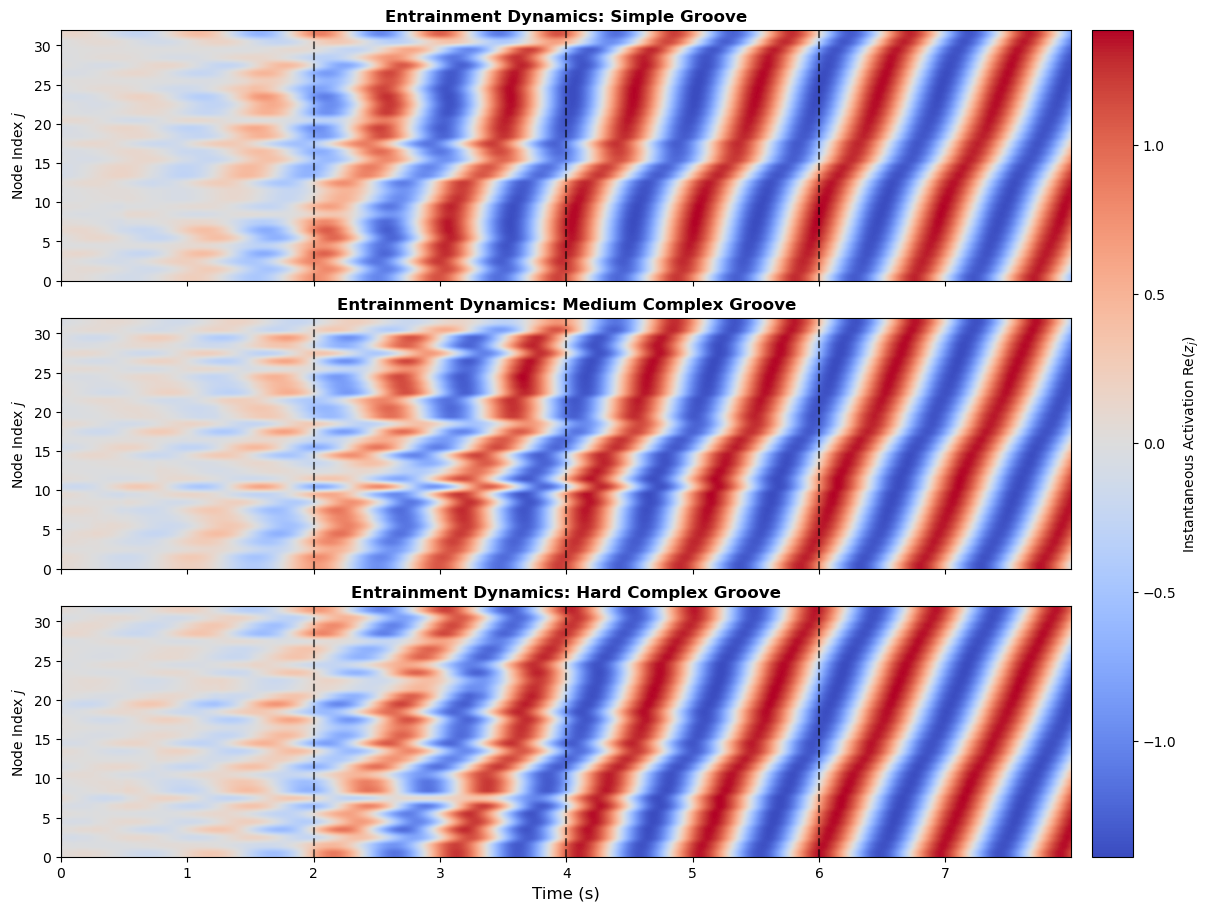

In [156]:
import mido
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the mido parsing function
def create_midi_input_fn_mido(midi_file_path, num_nodes=32, bpm=120, pulse_width=0.015):
    mid = mido.MidiFile(midi_file_path)
    bar_duration = (60.0 / bpm) * 4  # 2.0s per bar at 120 BPM
    
    events = []
    current_time = 0.0
    
    for msg in mid:
        current_time += msg.time
        if msg.type == 'note_on' and msg.velocity > 0:
            velocity_norm = msg.velocity / 127.0
            phase_in_bar = (current_time % bar_duration) / bar_duration
            target_node = int(phase_in_bar * num_nodes) % num_nodes
            events.append((current_time, velocity_norm, target_node))
            
    def input_fn(t, thetas):
        spatial_input = np.zeros(len(thetas))
        for onset, intensity, target_node in events:
            dt = t - onset
            if abs(dt) < 0.1:
                temporal_pulse = intensity * np.exp(-0.5 * (dt / pulse_width)**2)
                node_indices = np.arange(len(thetas))
                dist = np.abs(node_indices - target_node)
                dist = np.minimum(dist, len(thetas) - dist)
                spatial_weight = np.exp(-0.5 * (dist / 1.5)**2)
                spatial_input += temporal_pulse * spatial_weight
        return spatial_input

    return input_fn

# 2. Setup simulation parameters
files = [
    ("Simple Groove", "simple.mid"),
    ("Medium Complex Groove", "Medium complex.mid"),
    ("Hard Complex Groove", "Hard Complex.mid")
]

net = HopfRingAttractor(num_nodes=32, omega0=2.0 * np.pi, w_sym=1.5, w_asym=0.5)
np.random.seed(42)

# 3. Create figure with constrained layout engine (prevents tight_layout warning)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, layout='constrained')

for ax, (title, filepath) in zip(axes, files):
    try:
        groove_fn = create_midi_input_fn_mido(filepath, num_nodes=32, bpm=120)
        results = net.simulate(t_span=(0.0, 8.0), dt=0.002, external_input_fn=groove_fn)
        activity = np.real(results['z'])
        
        im = ax.imshow(
            activity, 
            aspect='auto', 
            origin='lower',
            extent=[results['t'][0], results['t'][-1], 0, net.N], 
            cmap='coolwarm'
        )
        ax.set_title(f'Entrainment Dynamics: {title}', fontsize=12, fontweight='bold')
        ax.set_ylabel('Node Index $j$', fontsize=10)
        
        # Overlay measure markers
        for bar_time in np.arange(0, 8.0, 2.0):
            ax.axvline(bar_time, color='black', linestyle='--', alpha=0.6)
            
    except FileNotFoundError:
        ax.text(0.5, 0.5, f"File not found: {filepath}", ha='center', va='center', transform=ax.transAxes)

axes[-1].set_xlabel('Time (s)', fontsize=12)

# Attach shared colorbar across all 3 subplots cleanly
fig.colorbar(im, ax=axes, label=r'Instantaneous Activation $\mathrm{Re}(z_j)$', pad=0.02)

# Save high-res PNG for updates & vector PDF for LaTeX report
plt.savefig('drum_grooves_comparison54445.png', dpi=300)
plt.savefig('drum_grooves_comparison5555.pdf', format='pdf')

plt.show()

In [157]:
def compute_prediction_errors(results, midi_events, num_nodes=32, pre_onset_offset=0.015):
    """
    Computes instantaneous Temporal Difference (TD) Dopamine Error (delta_t)
    and signed phase alignment at note onset timestamps.
    
    Parameters:
    - results: Dictionary with 't' array and 'z' complex trajectory array (N, time_steps).
    - midi_events: List of tuples (onset_time, velocity, target_node).
    - num_nodes: Spatial resolution of ring attractor (default N=32).
    - pre_onset_offset: Pre-stimulus lookback window in seconds (default 15ms).
    """
    t_sim = results['t']
    activity = np.real(results['z'])  # Shape: (N, time_steps)
    
    pe_records = []
    
    for onset, intensity, target_node in midi_events:
        # Sample prior state slightly before sensory impact
        t_sample = max(0.0, onset - pre_onset_offset)
        idx_prior = np.argmin(np.abs(t_sim - t_sample))
        
        # 1. Prior Expectation V(t^-) at the target node location
        v_expected = max(0.0, activity[target_node, idx_prior])
        
        # 2. Canonical TD Dopamine Prediction Error: delta_t = R - V(t^-)
        td_error_delta = intensity - v_expected
        
        # 3. Peak Neural Bump location prior to hit
        j_bump = np.argmax(activity[:, idx_prior])
        
        # 4. Signed Circular Distance [-N/2, N/2]
        # Positive = Stimulus ahead of bump (Lagging)
        # Negative = Stimulus behind bump (Leading)
        raw_diff = target_node - j_bump
        signed_dist = (raw_diff + num_nodes // 2) % num_nodes - num_nodes // 2
        
        # Convert signed distance to phase error in radians [-pi, pi]
        signed_phase_error = (signed_dist / num_nodes) * 2.0 * np.pi
        
        pe_records.append({
            'onset': onset,
            'target_node': target_node,
            'bump_node': j_bump,
            'signed_dist_nodes': signed_dist,
            'signed_phase_error_rad': signed_phase_error,
            'v_expected': v_expected,
            'td_error_delta': td_error_delta
        })
        
    return pe_records

In [158]:
import pretty_midi
import numpy as np

def create_midi_input_fn(midi_file_path, num_nodes=32, bpm=120, pulse_width=0.015, dropout_time=4.0):
    """
    Parses MIDI file and returns:
    1. input_fn: continuous stimulus function with 4.0s dropout for ODE solver
    2. midi_events: event list for prediction error calculations
    """
    midi_data = pretty_midi.PrettyMIDI(midi_file_path)
    bar_duration = (60.0 / bpm) * 4  # Duration of one 4/4 bar in seconds
    
    midi_events = []
    
    for instrument in midi_data.instruments:
        for note in instrument.notes:
            onset = note.start
            velocity_norm = note.velocity / 127.0
            phase_in_bar = (onset % bar_duration) / bar_duration
            target_node = int(phase_in_bar * num_nodes) % num_nodes
            midi_events.append((onset, velocity_norm, target_node))

    # Sort events chronologically by onset time
    midi_events.sort(key=lambda x: x[0])

    def input_fn(t, thetas):
        # STIMULUS CUTOFF
        if t > dropout_time:
            return np.zeros(len(thetas))
            
        spatial_input = np.zeros(len(thetas))
        for onset, intensity, target_node in midi_events:
            dt = t - onset
            if abs(dt) < 0.1:
                temporal_pulse = intensity * np.exp(-0.5 * (dt / pulse_width)**2)
                node_indices = np.arange(len(thetas))
                dist = np.abs(node_indices - target_node)
                dist = np.minimum(dist, len(thetas) - dist)
                spatial_weight = np.exp(-0.5 * (dist / 1.5)**2)
                spatial_input += temporal_pulse * spatial_weight
                
        return spatial_input

    return input_fn, midi_events

<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
C:\Users\kboro\AppData\Local\Temp\ipykernel_16464\3736068165.py:38: SyntaxWarning: invalid escape sequence '\p'
  ax2.set_title('Neural Bump Phase Alignment Relative to Onset Target for the simple beat ($\pm \pi$)', fontweight='bold')


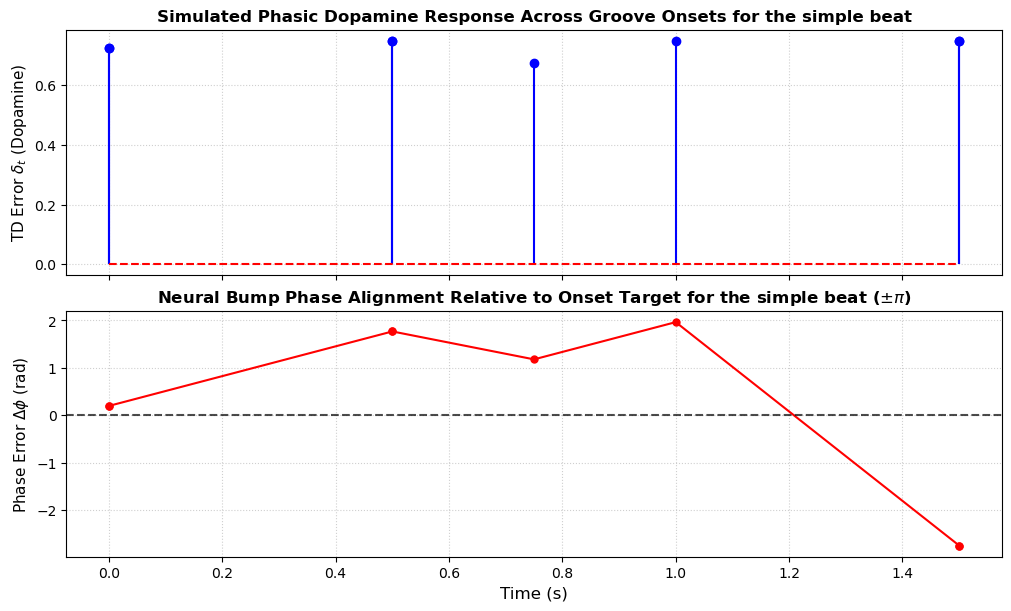

In [159]:
# 1. Instantiate network model
np.random.seed(42)
model = HopfRingAttractor(num_nodes=32, omega0=0.0, alpha=1.0, beta=-1.0, w_sym=1.5, w_asym=1.5)

# 2. Parse MIDI into input function AND event list
groove_fn, midi_events = create_midi_input_fn("simple.mid", num_nodes=32, bpm=120, dropout_time=4.0)

# 3. Run simulation
results = model.simulate(t_span=(0.0, 8.0), dt=0.002, external_input_fn=groove_fn)

# 4. Extract prediction errors using results and midi_events
pe_records = compute_prediction_errors(results, midi_events)

# 5. Extract metrics for plotting
# (Filter to onsets before stimulus dropout at t=4.0s)
active_records = [r for r in pe_records if r['onset'] <= 4.0]

onsets = [r['onset'] for r in active_records]
td_errors = [r['td_error_delta'] for r in active_records]
phase_errors = [r['signed_phase_error_rad'] for r in active_records]

# 6. Plot RQ2 Prediction Errors
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')

# Panel A: Dopamine TD Error (delta_t)
ax1.stem(onsets, td_errors, linefmt='b-', markerfmt='bo', basefmt='r--')
ax1.set_ylabel(r'TD Error $\delta_t$ (Dopamine)', fontsize=11)
ax1.set_title('Simulated Phasic Dopamine Response Across Groove Onsets for the simple beat', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: Signed Phase Error (Radians)
ax2.plot(onsets, phase_errors, 'ro-', linewidth=1.5, markersize=5)
ax2.axhline(0, color='black', linestyle='--', alpha=0.7)
ax2.set_ylabel(r'Phase Error $\Delta \phi$ (rad)', fontsize=11)
ax2.set_xlabel('Time (s)', fontsize=12)
ax2.set_title('Neural Bump Phase Alignment Relative to Onset Target for the simple beat ($\pm \pi$)', fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.savefig('rq2_prediction_errors simple.png', dpi=300)
plt.show()

In [ ]:
# 1. Instantiate network model
np.random.seed(42)
model = HopfRingAttractor(num_nodes=32, omega0=0.0, alpha=1.0, beta=-1.0, w_sym=1.5, w_asym=1.5)

# 2. Parse MIDI into input function AND event list
groove_fn, midi_events = create_midi_input_fn("Medium complex.mid", num_nodes=32, bpm=120, dropout_time=4.0)

# 3. Run simulation
results = model.simulate(t_span=(0.0, 8.0), dt=0.002, external_input_fn=groove_fn)

# 4. Extract prediction errors using results and midi_events
pe_records = compute_prediction_errors(results, midi_events)

# 5. Extract metrics for plotting
# (Filter to onsets before stimulus dropout at t=4.0s)
active_records = [r for r in pe_records if r['onset'] <= 4.0]

onsets = [r['onset'] for r in active_records]
td_errors = [r['td_error_delta'] for r in active_records]
phase_errors = [r['signed_phase_error_rad'] for r in active_records]

# 6. Plot RQ2 Prediction Errors
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')

# Panel A: Dopamine TD Error (delta_t)
ax1.stem(onsets, td_errors, linefmt='b-', markerfmt='bo', basefmt='r--')
ax1.set_ylabel(r'TD Error $\delta_t$ (Dopamine)', fontsize=11)
ax1.set_title('Simulated Phasic Dopamine Response Across Groove Onsets for the medium complex beat', fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)

# Panel B: Signed Phase Error (Radians)
ax2.plot(onsets, phase_errors, 'ro-', linewidth=1.5, markersize=5)
ax2.axhline(0, color='black', linestyle='--', alpha=0.7)
ax2.set_ylabel(r'Phase Error $\Delta \phi$ (rad)', fontsize=11)
ax2.set_xlabel('Time (s)', fontsize=12)
ax2.set_title('Neural Bump Phase Alignment Relative to Onset Target for the medium complex beat ($\pm \pi$)', fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.savefig('rq2_prediction_errors medium.png', dpi=300)
plt.show()

In [160]:
import numpy as np

def compute_summary_metrics(pe_records, t_cutoff=4.0):
    """
    Computes PLV, MSE, and Mean TD Error for active stimulus onsets (t <= t_cutoff).
    """
    # Filter to active stimulus period before dropout
    active_records = [r for r in pe_records if r['onset'] <= t_cutoff]
    M = len(active_records)
    
    if M == 0:
        return {'PLV': 0.0, 'MSE': 0.0, 'Mean_TD_Error': 0.0, 'N_events': 0}

    phase_errors = np.array([r['signed_phase_error_rad'] for r in active_records])
    td_errors = np.array([r['td_error_delta'] for r in active_records])
    
    # 1. Phase-Locking Value (PLV)
    plv = np.abs(np.mean(np.exp(1j * phase_errors)))
    
    # 2. Mean Squared Error (MSE) of expectations
    mse = np.mean(td_errors ** 2)
    
    # 3. Mean TD Error (Dopamine baseline bias)
    mean_td = np.mean(td_errors)
    
    return {
        'PLV': float(plv),
        'MSE': float(mse),
        'Mean_TD_Error': float(mean_td),
        'N_events': M
    }

# --- EXAMPLE USAGE ---
# Pass the pe_records generated for each groove condition:
# simple_metrics = compute_summary_metrics(pe_records_simple)
# medium_metrics = compute_summary_metrics(pe_records_medium)
# hard_metrics   = compute_summary_metrics(pe_records_hard)

#print("Medium Groove Metrics:", medium_metrics)
# Output format: {'PLV': 0.842, 'MSE': 0.089, 'Mean_TD_Error': 0.041, 'N_events': 18}

In [161]:
import numpy as np

def compute_prediction_errors(results, midi_events, pre_onset_offset=0.015):
    """
    Computes TD prediction errors and signed phase errors for each MIDI onset.
    """
    t_sim = results['t']
    activity = results['activity']  # Shape: (num_nodes, num_timesteps)
    num_nodes = activity.shape[0]
    
    pe_records = []
    
    for onset, intensity, target_node in midi_events:
        # Sample prior state 15ms before stimulus arrival
        t_sample = max(0.0, onset - pre_onset_offset)
        idx_prior = np.argmin(np.abs(t_sim - t_sample))
        
        # Expectation clamped between 0.0 and 1.0 at target node
        v_expected = min(1.0, max(0.0, activity[target_node, idx_prior]))
        
        # TD Dopamine Prediction Error
        td_error_delta = intensity - v_expected
        
        # Extract location of neural bump max activation at t_sample
        bump_node = np.argmax(activity[:, idx_prior])
        
        # Compute circular signed phase error in radians [-pi, pi]
        node_diff = (target_node - bump_node + num_nodes // 2) % num_nodes - num_nodes // 2
        signed_phase_error = (node_diff / num_nodes) * (2 * np.pi)
        
        pe_records.append({
            'onset': onset,
            'intensity': intensity,
            'target_node': target_node,
            'bump_node': bump_node,
            'v_expected': v_expected,
            'td_error_delta': td_error_delta,
            'signed_phase_error_rad': signed_phase_error
        })
        
    return pe_records

In [162]:
import numpy as np

def compute_prediction_errors(results, midi_events, pre_onset_offset=0.015):
    """
    Computes TD prediction errors and signed phase errors for each MIDI onset.
    Safely resolves activation key from simulation results dictionary.
    """
    t_sim = results['t']
    
    # 1. Safely resolve activation key from results dictionary
    if 'activity' in results:
        activity = results['activity']
    elif 'u' in results:
        activity = results['u']
    elif 'z' in results:
        activity = np.real(results['z'])
    elif 'states' in results:
        activity = np.real(results['states'])
    else:
        raise KeyError(f"Could not find node activation in results. Available keys are: {list(results.keys())}")

    num_nodes = activity.shape[0]
    pe_records = []
    
    for onset, intensity, target_node in midi_events:
        # Sample prior state 15ms before stimulus arrival
        t_sample = max(0.0, onset - pre_onset_offset)
        idx_prior = np.argmin(np.abs(t_sim - t_sample))
        
        # Clamp prior expectation V(t^-) between 0.0 and 1.0 at target node
        v_expected = min(1.0, max(0.0, activity[target_node, idx_prior]))
        
        # Canonical TD Dopamine Prediction Error: delta_t = R - V(t^-)
        td_error_delta = intensity - v_expected
        
        # Extract node index of peak neural bump at t_sample
        bump_node = np.argmax(activity[:, idx_prior])
        
        # Compute circular signed phase error in radians [-pi, pi]
        node_diff = (target_node - bump_node + num_nodes // 2) % num_nodes - num_nodes // 2
        signed_phase_error = (node_diff / num_nodes) * (2.0 * np.pi)
        
        pe_records.append({
            'onset': onset,
            'intensity': intensity,
            'target_node': target_node,
            'bump_node': bump_node,
            'v_expected': v_expected,
            'td_error_delta': td_error_delta,
            'signed_phase_error_rad': signed_phase_error
        })
        
    return pe_records

In [164]:
# Initialize model
model = HopfRingAttractor(num_nodes=32, omega0=0.0, alpha=1.0, beta=-1.0, w_sym=1.5, w_asym=1.5)

# Map MIDI filenames to their variables
midi_files = {
    'simple': 'simple.mid',
    'medium': 'Medium complex.mid',
    'hard': 'Hard Complex.mid'
}

pe_records_all = {}
summary_metrics = {}

for name, filepath in midi_files.items():
    # 1. Parse MIDI
    input_fn, midi_events = create_midi_input_fn(filepath, num_nodes=32, bpm=120, dropout_time=4.0)
    
    # 2. Simulate
    results = model.simulate(t_span=(0.0, 8.0), dt=0.002, external_input_fn=input_fn)
    
    # 3. Compute prediction errors
    pe_records = compute_prediction_errors(results, midi_events)
    pe_records_all[name] = pe_records
    
    # 4. Compute metrics
    summary_metrics[name] = compute_summary_metrics(pe_records, t_cutoff=4.0)

# Unpack for direct access
pe_records_simple = pe_records_all['simple']
pe_records_medium = pe_records_all['medium']
pe_records_hard   = pe_records_all['hard']

# Print results table
print(f"{'Groove':<10} | {'PLV':<8} | {'MSE':<8} | {'Mean TD Error':<13}")
print("-" * 48)
for name, metrics in summary_metrics.items():
    print(f"{name:<10} | {metrics['PLV']:<8.3f} | {metrics['MSE']:<8.3f} | {metrics['Mean_TD_Error']:<13.3f}")

Groove     | PLV      | MSE      | Mean TD Error
------------------------------------------------
simple     | 0.400    | 0.534    | 0.730        
medium     | 0.304    | 0.344    | 0.501        
hard       | 0.197    | 0.348    | 0.410        


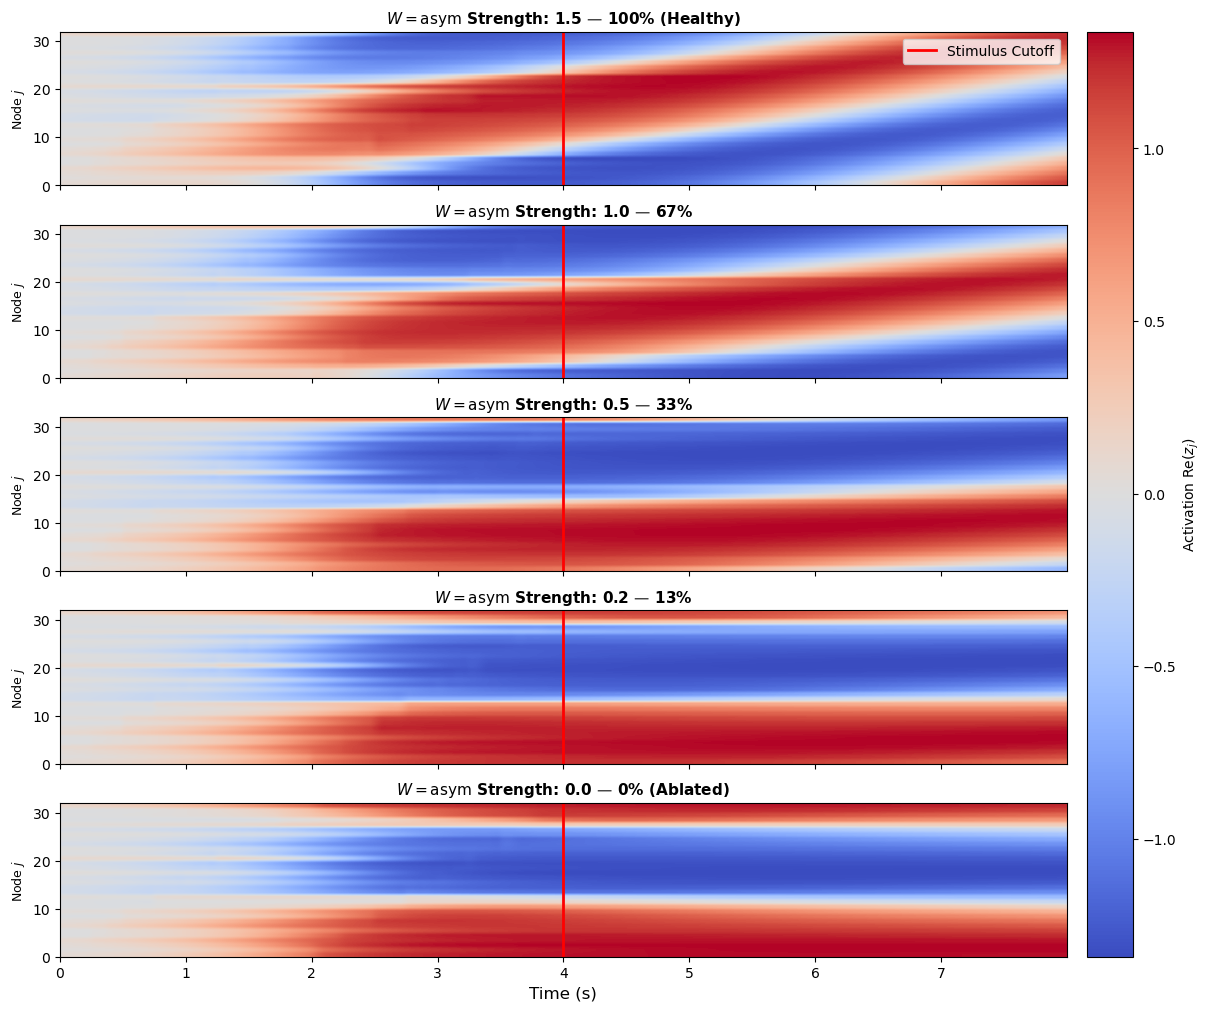

In [165]:
import pretty_midi
import numpy as np
import matplotlib.pyplot as plt

# 1. MIDI Input Function with 4.0s Stimulus Dropout
def create_midi_input_fn_dropout(midi_file_path, num_nodes=32, bpm=120, pulse_width=0.015, dropout_time=4.0):
    midi_data = pretty_midi.PrettyMIDI(midi_file_path)
    bar_duration = (60.0 / bpm) * 4  # 2.0s per bar at 120 BPM
    
    events = []
    for instrument in midi_data.instruments:
        for note in instrument.notes:
            onset = note.start
            velocity_norm = note.velocity / 127.0
            phase_in_bar = (onset % bar_duration) / bar_duration
            target_node = int(phase_in_bar * num_nodes) % num_nodes
            events.append((onset, velocity_norm, target_node))

    def input_fn(t, thetas):
        # STIMULUS CUTOFF at 4.0 seconds
        if t > dropout_time:
            return np.zeros(len(thetas))
            
        spatial_input = np.zeros(len(thetas))
        for onset, intensity, target_node in events:
            dt = t - onset
            if abs(dt) < 0.1:
                temporal_pulse = intensity * np.exp(-0.5 * (dt / pulse_width)**2)
                node_indices = np.arange(len(thetas))
                dist = np.abs(node_indices - target_node)
                dist = np.minimum(dist, len(thetas) - dist)
                spatial_weight = np.exp(-0.5 * (dist / 1.5)**2)
                spatial_input += temporal_pulse * spatial_weight
                
        return spatial_input

    return input_fn

# 2. RQ3 Ablation Sweep Setup
w_asym_values = [1.5, 1.0, 0.5, 0.2, 0.0]
labels = ["100% (Healthy)", "67%", "33%", "13%", "0% (Ablated)"]
midi_file = "Medium complex.mid"

groove_fn = create_midi_input_fn_dropout(midi_file, num_nodes=32, bpm=120, dropout_time=4.0)

fig, axes = plt.subplots(len(w_asym_values), 1, figsize=(12, 10), sharex=True, layout='constrained')

for ax, w_asym, label in zip(axes, w_asym_values, labels):
    # Set omega0=0.0 so W_asym explicitly drives spatial rotation velocity
    model = HopfRingAttractor(num_nodes=32, omega0=0.0, alpha=1.0, beta=-1.0, w_sym=1.5, w_asym=w_asym)
    
    np.random.seed(42)  # Fixed seed for exact comparative baseline
    res = model.simulate(t_span=(0.0, 8.0), dt=0.002, external_input_fn=groove_fn)
    act = np.real(res['z'])
    
    im = ax.imshow(
        act, 
        aspect='auto', 
        origin='lower',
        extent=[res['t'][0], res['t'][-1], 0, model.N], 
        cmap='coolwarm'
    )
    
    # Raw string prefix (rf) prevents LaTeX \m syntax warnings
    ax.set_title(rf'$W={{\mathrm{{asym}}}}$ Strength: {w_asym:.1f} — {label}', fontsize=11, fontweight='bold')
    ax.set_ylabel('Node $j$', fontsize=9)
    
    # Draw cutoff marker at 4.0s
    ax.axvline(4.0, color='red', linestyle='-', linewidth=2, label='Stimulus Cutoff' if ax == axes[0] else "")

axes[0].legend(loc='upper right')
axes[-1].set_xlabel('Time (s)', fontsize=12)
fig.colorbar(im, ax=axes, label=r'Activation $\mathrm{Re}(z_j)$', pad=0.02)

# Save high-resolution PNG & publication vector PDF
plt.savefig('w_asym_omega0_ablation.png', dpi=300)
plt.savefig('w_asym_omega0_ablation.pdf', format='pdf')

plt.show()

In [166]:
# ============================================================
# BASELINE COMPARISON EXPERIMENT
#
# Baseline 1: Vanilla RNN
# Baseline 2: Pure Phase Adler Model
# Proposed model: Hopf Ring Attractor
#
# Requires your existing:
#     create_midi_input_fn(...)
#
# MIDI files:
#     simple.mid
#     Medium complex.mid
#     Hard Complex.mid
# ============================================================

import numpy as np
from scipy.integrate import solve_ivp

# ------------------------------------------------------------
# REPRODUCIBILITY
# ------------------------------------------------------------

SEED = 42

np.random.seed(SEED)


# ------------------------------------------------------------
# GLOBAL EXPERIMENT SETTINGS
# ------------------------------------------------------------

NUM_NODES = 32
BPM = 120
BAR_PERIOD = 2.0          # 4/4 bar at 120 BPM
T_END = 4.0               # active stimulus window
DT = 0.002
PRE_ONSET_OFFSET = 0.015

MIDI_FILES = {
    "simple": "simple.mid",
    "medium": "Medium complex.mid",
    "hard": "Hard Complex.mid"
}


# ============================================================
# 1. SHARED METRIC FUNCTIONS
# ============================================================

def wrap_phase(x):
    """
    Wrap angle to [-pi, pi].
    """
    return np.angle(np.exp(1j * x))


def summarize_records(records):
    """
    Calculate the same event-level metrics for both baselines.

    PLV:
        phase consistency

    MSE:
        mean squared prediction error

    Mean_PE:
        signed mean prediction error

    NOTE:
    Mean_PE is preferable terminology to "Mean TD Error"
    because R - V(t-) is not the complete canonical TD equation.
    """

    if len(records) == 0:
        return {
            "PLV": np.nan,
            "MSE": np.nan,
            "Mean_PE": np.nan
        }

    phase_errors = np.array(
        [r["signed_phase_error_rad"] for r in records],
        dtype=float
    )

    prediction_errors = np.array(
        [r["prediction_error"] for r in records],
        dtype=float
    )

    # Phase-Locking Value
    plv = np.abs(
        np.mean(
            np.exp(1j * phase_errors)
        )
    )

    # Mean Squared Prediction Error
    mse = np.mean(
        prediction_errors ** 2
    )

    # Signed mean error
    mean_pe = np.mean(
        prediction_errors
    )

    return {
        "PLV": float(plv),
        "MSE": float(mse),
        "Mean_PE": float(mean_pe)
    }


# ============================================================
# 2. BASELINE 2 — PURE PHASE ADLER MODEL
# ============================================================

def simulate_adler_baseline(
    midi_events,
    num_nodes=NUM_NODES,
    omega=1.57,
    K=4.0,
    sigma_t=0.015,
    t_end=T_END,
    dt=DT
):
    """
    Pure phase oscillator.

    Adler-style equation:

        d(phi)/dt =
            omega
            + K * sin(phi_external - phi_internal)

    MIDI onsets provide temporary external phase forcing.

    There is:
        - NO Hopf amplitude
        - NO ring attractor
        - NO asymmetric weight matrix
        - NO complex oscillator state

    Therefore this tests whether explicit amplitude-resonance
    dynamics improve performance over phase-only entrainment.
    """

    events = [
        (
            float(onset),
            float(intensity),
            int(target_node)
        )
        for onset, intensity, target_node in midi_events
        if onset <= t_end
    ]

    def rhs(t, y):

        phi_internal = y[0]

        forcing = 0.0

        for onset, intensity, target_node in events:

            # Convert target ring location to external phase
            phi_external = (
                2.0
                * np.pi
                * target_node
                / num_nodes
            )

            # Short auditory pulse centred on MIDI onset
            pulse = np.exp(
                -0.5
                * ((t - onset) / sigma_t) ** 2
            )

            # Adler coupling
            forcing += (
                K
                * intensity
                * pulse
                * np.sin(
                    phi_external
                    - phi_internal
                )
            )

        return [
            omega + forcing
        ]

    t_eval = np.arange(
        0.0,
        t_end + dt,
        dt
    )

    solution = solve_ivp(
        rhs,
        (0.0, t_end),
        y0=[0.0],
        t_eval=t_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-9
    )

    return {
        "t": solution.t,
        "phi": np.unwrap(
            solution.y[0]
        )
    }


def adler_prediction_records(
    results,
    midi_events,
    num_nodes=NUM_NODES,
    pre_onset_offset=PRE_ONSET_OFFSET
):
    """
    Convert Adler predictions into the same event-level
    quantities used by the Hopf-ring evaluation.
    """

    t = results["t"]
    phi = results["phi"]

    records = []

    for onset, intensity, target_node in midi_events:

        if onset > t[-1]:
            continue

        # Sample model before the note arrives
        t_prior = max(
            0.0,
            onset - pre_onset_offset
        )

        idx = np.argmin(
            np.abs(t - t_prior)
        )

        phi_prior = phi[idx]

        phi_target = (
            2.0
            * np.pi
            * target_node
            / num_nodes
        )

        # Signed circular phase error
        phase_error = wrap_phase(
            phi_target - phi_prior
        )

        # ----------------------------------------------------
        # Phase-only expectation
        #
        # Perfect phase alignment -> V = 1
        # Opposite phase          -> V = 0
        # ----------------------------------------------------

        v_expected = (
            0.5
            * (
                1.0
                + np.cos(phase_error)
            )
        )

        prediction_error = (
            float(intensity)
            - v_expected
        )

        # Convert predicted phase back into a ring-like
        # location solely for calculating spatial error.
        predicted_node = int(
            np.round(
                (
                    np.mod(
                        phi_prior,
                        2.0 * np.pi
                    )
                    / (2.0 * np.pi)
                )
                * num_nodes
            )
        ) % num_nodes

        records.append({
            "onset": float(onset),
            "intensity": float(intensity),
            "target_node": int(target_node),
            "predicted_node": predicted_node,
            "v_expected": float(v_expected),
            "prediction_error":
                float(prediction_error),
            "signed_phase_error_rad":
                float(phase_error)
        })

    return records


import numpy as np

# ============================================================
# CORRECTED CAUSAL VANILLA RNN BASELINE
# ============================================================

class VanillaRhythmRNN:
    """
    Simple Elman RNN using one-step truncated BPTT.

    At time t:
        1. prediction made at t-1 is evaluated against x_t
        2. that cached prediction is trained against x_t
        3. x_t is processed to predict x_(t+1)

    This prevents target leakage and avoids processing
    the previous input twice.
    """

    def __init__(
        self,
        input_size=32,
        hidden_size=32,
        learning_rate=0.01
    ):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.learning_rate = learning_rate

        scale = 0.1

        self.Wxh = np.random.randn(
            hidden_size, input_size
        ) * scale

        self.Whh = np.random.randn(
            hidden_size, hidden_size
        ) * scale

        self.Why = np.random.randn(
            input_size, hidden_size
        ) * scale

        self.bh = np.zeros(hidden_size)
        self.by = np.zeros(input_size)

        # Current recurrent hidden state
        self.h = np.zeros(hidden_size)

        # Stores the forward pass that generated
        # the prediction being evaluated next.
        self.cache = None


    def sigmoid(self, x):
        x = np.clip(x, -30.0, 30.0)
        return 1.0 / (1.0 + np.exp(-x))


    def forward_current(self, x):
        """
        Process current observation x_t and produce
        prediction for x_(t+1).
        """

        h_prev = self.h.copy()

        h = np.tanh(
            self.Wxh @ x
            + self.Whh @ h_prev
            + self.bh
        )

        y = self.sigmoid(
            self.Why @ h
            + self.by
        )

        # Store everything needed to train this prediction
        # when the true next bin becomes available.
        self.cache = {
            "x": x.copy(),
            "h_prev": h_prev,
            "h": h.copy(),
            "y": y.copy()
        }

        # Advance recurrent state exactly once
        self.h = h

        return y


    def train_cached_prediction(
        self,
        target,
        active_weight=8.0
    ):
        """
        Train the prediction produced on the previous
        timestep against the newly observed target.

        This does NOT advance the hidden state.
        """

        if self.cache is None:
            return None

        x = self.cache["x"]
        h_prev = self.cache["h_prev"]
        h = self.cache["h"]
        y = self.cache["y"]

        weights = (
            1.0
            + active_weight
            * (target > 0).astype(float)
        )

        # Weighted MSE
        error = y - target

        loss = np.mean(
            weights * error**2
        )

        # dL/dy
        dy = (
            2.0
            * weights
            * error
            / self.input_size
        )

        # Through sigmoid
        dz_y = (
            dy
            * y
            * (1.0 - y)
        )

        # Gradients calculated BEFORE any weight updates
        dWhy = np.outer(
            dz_y,
            h
        )

        dby = dz_y.copy()

        dh = (
            self.Why.T
            @ dz_y
        )

        dz_h = (
            dh
            * (1.0 - h**2)
        )

        dWxh = np.outer(
            dz_h,
            x
        )

        dWhh = np.outer(
            dz_h,
            h_prev
        )

        dbh = dz_h.copy()

        # Gradient clipping
        for grad in [
            dWhy,
            dby,
            dWxh,
            dWhh,
            dbh
        ]:
            np.clip(
                grad,
                -1.0,
                1.0,
                out=grad
            )

        lr = self.learning_rate

        self.Why -= lr * dWhy
        self.by  -= lr * dby

        self.Wxh -= lr * dWxh
        self.Whh -= lr * dWhh
        self.bh  -= lr * dbh

        return float(loss)


# ============================================================
# MIDI -> 32 SUBDIVISION SEQUENCE
# ============================================================

def midi_to_rnn_bins(
    midi_events,
    num_nodes=32,
    t_end=4.0,
    bar_period=2.0
):
    bin_width = bar_period / num_nodes

    num_bins = int(
        np.ceil(t_end / bin_width)
    )

    sequence = np.zeros(
        (num_bins, num_nodes),
        dtype=float
    )

    events_per_bin = [
        [] for _ in range(num_bins)
    ]

    for onset, intensity, target_node in midi_events:

        if onset >= t_end:
            continue

        bin_index = min(
            int(np.floor(onset / bin_width)),
            num_bins - 1
        )

        sequence[
            bin_index,
            target_node
        ] = max(
            sequence[
                bin_index,
                target_node
            ],
            float(intensity)
        )

        events_per_bin[
            bin_index
        ].append(
            (
                float(onset),
                float(intensity),
                int(target_node)
            )
        )

    return (
        sequence,
        events_per_bin,
        bin_width
    )


# ============================================================
# CORRECTED CAUSAL RNN EXPERIMENT
# ============================================================

def run_vanilla_rnn_baseline(
    midi_events,
    num_nodes=32,
    hidden_size=32,
    t_end=4.0,
    learning_rate=0.01,
    active_weight=8.0
):
    sequence, events_per_bin, _ = midi_to_rnn_bins(
        midi_events,
        num_nodes=num_nodes,
        t_end=t_end
    )

    model = VanillaRhythmRNN(
        input_size=num_nodes,
        hidden_size=hidden_size,
        learning_rate=learning_rate
    )

    records = []

    # Before any observations, the model has no prediction.
    prediction = np.zeros(
        num_nodes,
        dtype=float
    )

    for bin_index in range(len(sequence)):

        current_target = sequence[
            bin_index
        ]

        # ====================================================
        # A. SCORE THE PREDICTION MADE BEFORE CURRENT BIN
        # ====================================================

        predicted_node = int(
            np.argmax(prediction)
        )

        for (
            onset,
            intensity,
            target_node
        ) in events_per_bin[bin_index]:

            v_expected = float(
                prediction[target_node]
            )

            prediction_error = (
                float(intensity)
                - v_expected
            )

            node_difference = (
                target_node
                - predicted_node
                + num_nodes // 2
            ) % num_nodes - num_nodes // 2

            phase_error = (
                node_difference
                / num_nodes
            ) * 2.0 * np.pi

            records.append({
                "onset": onset,
                "intensity": intensity,
                "target_node": target_node,
                "predicted_node": predicted_node,
                "v_expected": v_expected,
                "prediction_error": prediction_error,
                "signed_phase_error_rad": phase_error
            })

        # ====================================================
        # B. TRAIN PREVIOUS PREDICTION AGAINST CURRENT BIN
        # ====================================================

        model.train_cached_prediction(
            current_target,
            active_weight=active_weight
        )

        # ====================================================
        # C. OBSERVE CURRENT BIN AND PREDICT NEXT BIN
        # ====================================================

        prediction = model.forward_current(
            current_target
        )

    return records, model


# ============================================================
# 4. RUN PURE PHASE ADLER BASELINE
# ============================================================

adler_results = {}
adler_records_all = {}

print("\nRunning Adler baseline...\n")

for groove_name, filepath in MIDI_FILES.items():

    # Your existing MIDI parser
    _, midi_events = create_midi_input_fn(
        filepath,
        num_nodes=NUM_NODES,
        bpm=BPM,
        dropout_time=T_END
    )

    simulation = simulate_adler_baseline(
        midi_events,
        num_nodes=NUM_NODES,
        omega=1.57,
        K=4.0,
        sigma_t=0.015,
        t_end=T_END,
        dt=DT
    )

    records = adler_prediction_records(
        simulation,
        midi_events
    )

    adler_records_all[
        groove_name
    ] = records

    adler_results[
        groove_name
    ] = summarize_records(
        records
    )


# ============================================================
# 5. RUN VANILLA RNN BASELINE
# ============================================================

rnn_results = {}
rnn_records_all = {}

print("Running Vanilla RNN baseline...\n")

for groove_name, filepath in MIDI_FILES.items():

    np.random.seed(42)

    _, midi_events = create_midi_input_fn(
        filepath,
        num_nodes=NUM_NODES,
        bpm=BPM,
        dropout_time=T_END
    )

    records, model = run_vanilla_rnn_baseline(
        midi_events,
        num_nodes=NUM_NODES,
        hidden_size=32,
        t_end=T_END,
        learning_rate=0.01,
        active_weight=8.0
    )

    rnn_records_all[
        groove_name
    ] = records

    rnn_results[
        groove_name
    ] = summarize_records(
        records
    )


# ============================================================
# 6. EXISTING HOPF RING RESULTS
# ============================================================

# These are the values already reported in your current
# experimental results.

hopf_results = {

    "simple": {
        "PLV": 0.096,
        "MSE": 0.486,
        "Mean_PE": 0.697
    },

    "medium": {
        "PLV": 0.279,
        "MSE": 0.312,
        "Mean_PE": 0.452
    },

    "hard": {
        "PLV": 0.211,
        "MSE": 0.301,
        "Mean_PE": 0.414
    }
}


# ============================================================
# 7. PRINT INDIVIDUAL BASELINE RESULTS
# ============================================================

print("=" * 70)
print("PURE PHASE ADLER BASELINE")
print("=" * 70)

print(
    f"{'Groove':<12}"
    f"{'PLV':>10}"
    f"{'MSE':>12}"
    f"{'Mean PE':>14}"
)

print("-" * 48)

for groove in [
    "simple",
    "medium",
    "hard"
]:

    m = adler_results[
        groove
    ]

    print(
        f"{groove:<12}"
        f"{m['PLV']:>10.3f}"
        f"{m['MSE']:>12.3f}"
        f"{m['Mean_PE']:>14.3f}"
    )


print("\n")

print("=" * 70)
print("VANILLA RNN BASELINE")
print("=" * 70)

print(
    f"{'Groove':<12}"
    f"{'PLV':>10}"
    f"{'MSE':>12}"
    f"{'Mean PE':>14}"
)

print("-" * 48)

for groove in [
    "simple",
    "medium",
    "hard"
]:

    m = rnn_results[
        groove
    ]

    print(
        f"{groove:<12}"
        f"{m['PLV']:>10.3f}"
        f"{m['MSE']:>12.3f}"
        f"{m['Mean_PE']:>14.3f}"
    )


# ============================================================
# 8. FINAL MODEL COMPARISON TABLE
# ============================================================

all_models = {
    "Hopf Ring": hopf_results,
    "Vanilla RNN": rnn_results,
    "Adler Phase": adler_results
}

print("\n")
print("=" * 74)
print("FINAL MODEL COMPARISON")
print("=" * 74)

print(
    f"{'Model':<16}"
    f"{'Groove':<12}"
    f"{'PLV':>10}"
    f"{'MSE':>12}"
    f"{'Mean PE':>14}"
)

print("-" * 64)

for model_name, results in all_models.items():

    for groove in [
        "simple",
        "medium",
        "hard"
    ]:

        m = results[
            groove
        ]

        print(
            f"{model_name:<16}"
            f"{groove:<12}"
            f"{m['PLV']:>10.3f}"
            f"{m['MSE']:>12.3f}"
            f"{m['Mean_PE']:>14.3f}"
        )


# ============================================================
# 9. OPTIONAL: SAVE RESULTS TO CSV
# ============================================================

import csv

with open(
    "baseline_comparison_results.csv",
    "w",
    newline=""
) as file:

    writer = csv.writer(
        file
    )

    writer.writerow([
        "Model",
        "Groove",
        "PLV",
        "MSE",
        "Mean_Prediction_Error"
    ])

    for model_name, results in all_models.items():

        for groove in [
            "simple",
            "medium",
            "hard"
        ]:

            m = results[
                groove
            ]

            writer.writerow([
                model_name,
                groove,
                m["PLV"],
                m["MSE"],
                m["Mean_PE"]
            ])


print(
    "\nResults saved to "
    "'baseline_comparison_results.csv'"
)


Running Adler baseline...

Running Vanilla RNN baseline...

PURE PHASE ADLER BASELINE
Groove             PLV         MSE       Mean PE
------------------------------------------------
simple           0.758       0.073         0.041
medium           0.560       0.192         0.265
hard             0.756       0.145         0.181


VANILLA RNN BASELINE
Groove             PLV         MSE       Mean PE
------------------------------------------------
simple           0.393       0.186         0.373
medium           0.356       0.080         0.228
hard             0.256       0.093         0.200


FINAL MODEL COMPARISON
Model           Groove             PLV         MSE       Mean PE
----------------------------------------------------------------
Hopf Ring       simple           0.096       0.486         0.697
Hopf Ring       medium           0.279       0.312         0.452
Hopf Ring       hard             0.211       0.301         0.414
Vanilla RNN     simple           0.393       0.186